In [1]:
from run_experiment import run_experiment_single_class, build_dataloaders, build_model
from utils.visualization import visualize_anomalies
from utils.helpers import set_seed, get_device
from utils.data_split import split_data
from losses import MSELoss
import pandas as pd

W1107 22:32:05.128000 14840 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


In [ ]:
config = {

    'experiment_name': 'baseline',

    'device': 'cuda',
    'num_workers': 0,
    'seed': 42,
    'cache_data' : True,

    # dataset
    'img_size': (256, 256),
    'batch_size': 16,

    # training
    'loss_fn': MSELoss,
    'learning_rate': 1e-3,
    'patience': 7,

    # model
    'model_name': 'Autoencoder',
    'base_channels': 16,
    'num_epochs': 70,
    'output_dir': './experiments/pixel_reconstruction',
    'class_name': 'bottle',  # Specify the class name for training and evaluation
}

In [ ]:
set_seed(config['seed'])
DEVICE = get_device(config['device'])
print(f"Using device: {DEVICE}")

Random seed set to 42.
Using device: cuda


### Train-Validation split
The MVTec AD dataset does not provide an official validation set. Therefore, a validation set is created by partitioning the original training set, which contains only defect-free (normal) images. The resulting validation set is used to monitor overfitting and implement early stopping. The test set is kept separate and used exclusively for final evaluation.

In [4]:
do_split = False  # Set to True if you want to split the dataset into training and validation sets
if do_split:
    # Split a single class
    #split_data(root="./data/MVTec", class_name="bottle", val_ratio=0.15)

    # Or split all classes under data/MVTec at once:
    split_data(root="./data/MVTec", val_ratio=0.15)

### Model Training and Evaluation

In [5]:
# history, metrics = run_experiment_single_class('wood', config)

# print("Training and evaluation completed.")
# print("Metrics:", metrics)


In [6]:
classes_to_run = ['cable', 'capsule', 'carpet', 'grid', 'hazelnut', 'leather', 'metal_nut', 'pill', 'screw', 'tile', 'toothbrush', 'transistor', 'wood', 'zipper', 'bottle']  # List of classes to run experiments on
all_results = {}

for cls in classes_to_run:
    history, metrics = run_experiment_single_class(cls, config)
    all_results[cls] = metrics


==============================  Starting class: CABLE  ==============================
Training Autoencoder for class 'cable' on device: cuda


Training:  69%|██████▊   | 48/70 [00:35<00:16,  1.34it/s, train_loss=0.0038, val_loss=0.0041]


Early stopping triggered at epoch 49


Evaluating: 100%|██████████| 10/10 [00:06<00:00,  1.48it/s]



==============================  Starting class: CAPSULE  ==============================
Training Autoencoder for class 'capsule' on device: cuda


Training:  54%|█████▍    | 38/70 [00:29<00:24,  1.30it/s, train_loss=0.0003, val_loss=0.0003]


... (40 outputs left out)

Early stopping triggered at epoch 63


Evaluating: 100%|██████████| 10/10 [00:05<00:00,  1.89it/s]



==============================  Starting class: BOTTLE  ==============================
Training Autoencoder for class 'bottle' on device: cuda


Evaluating: 100%|██████████| 6/6 [00:02<00:00,  2.75it/s]


In [7]:
df_results = pd.DataFrame.from_dict(all_results, orient='index')
df_results.loc['MEAN'] = df_results.mean()

# results_csv = Path(config['exp_root']) / "benchmark_results.csv"
# df_results.to_csv(results_csv)

display(df_results.round(4))

,image_auroc,pixel_auroc,aupro
cable,0.5234,0.5511,0.4017
capsule,0.4763,0.8938,0.7907
carpet,0.5991,0.8327,0.4793
grid,0.7561,0.9346,0.8244
hazelnut,0.9146,0.9797,0.9440
leather,0.6885,0.8740,0.7592
metal_nut,0.5108,0.7504,0.4324
pill,0.7556,0.9362,0.8975
screw,0.5751,0.9617,0.8593
tile,0.6093,0.5846,0.3046


Loaded model weights from experiments/pixel_reconstruction/baseline/capsule/checkpoints/best_model.pth


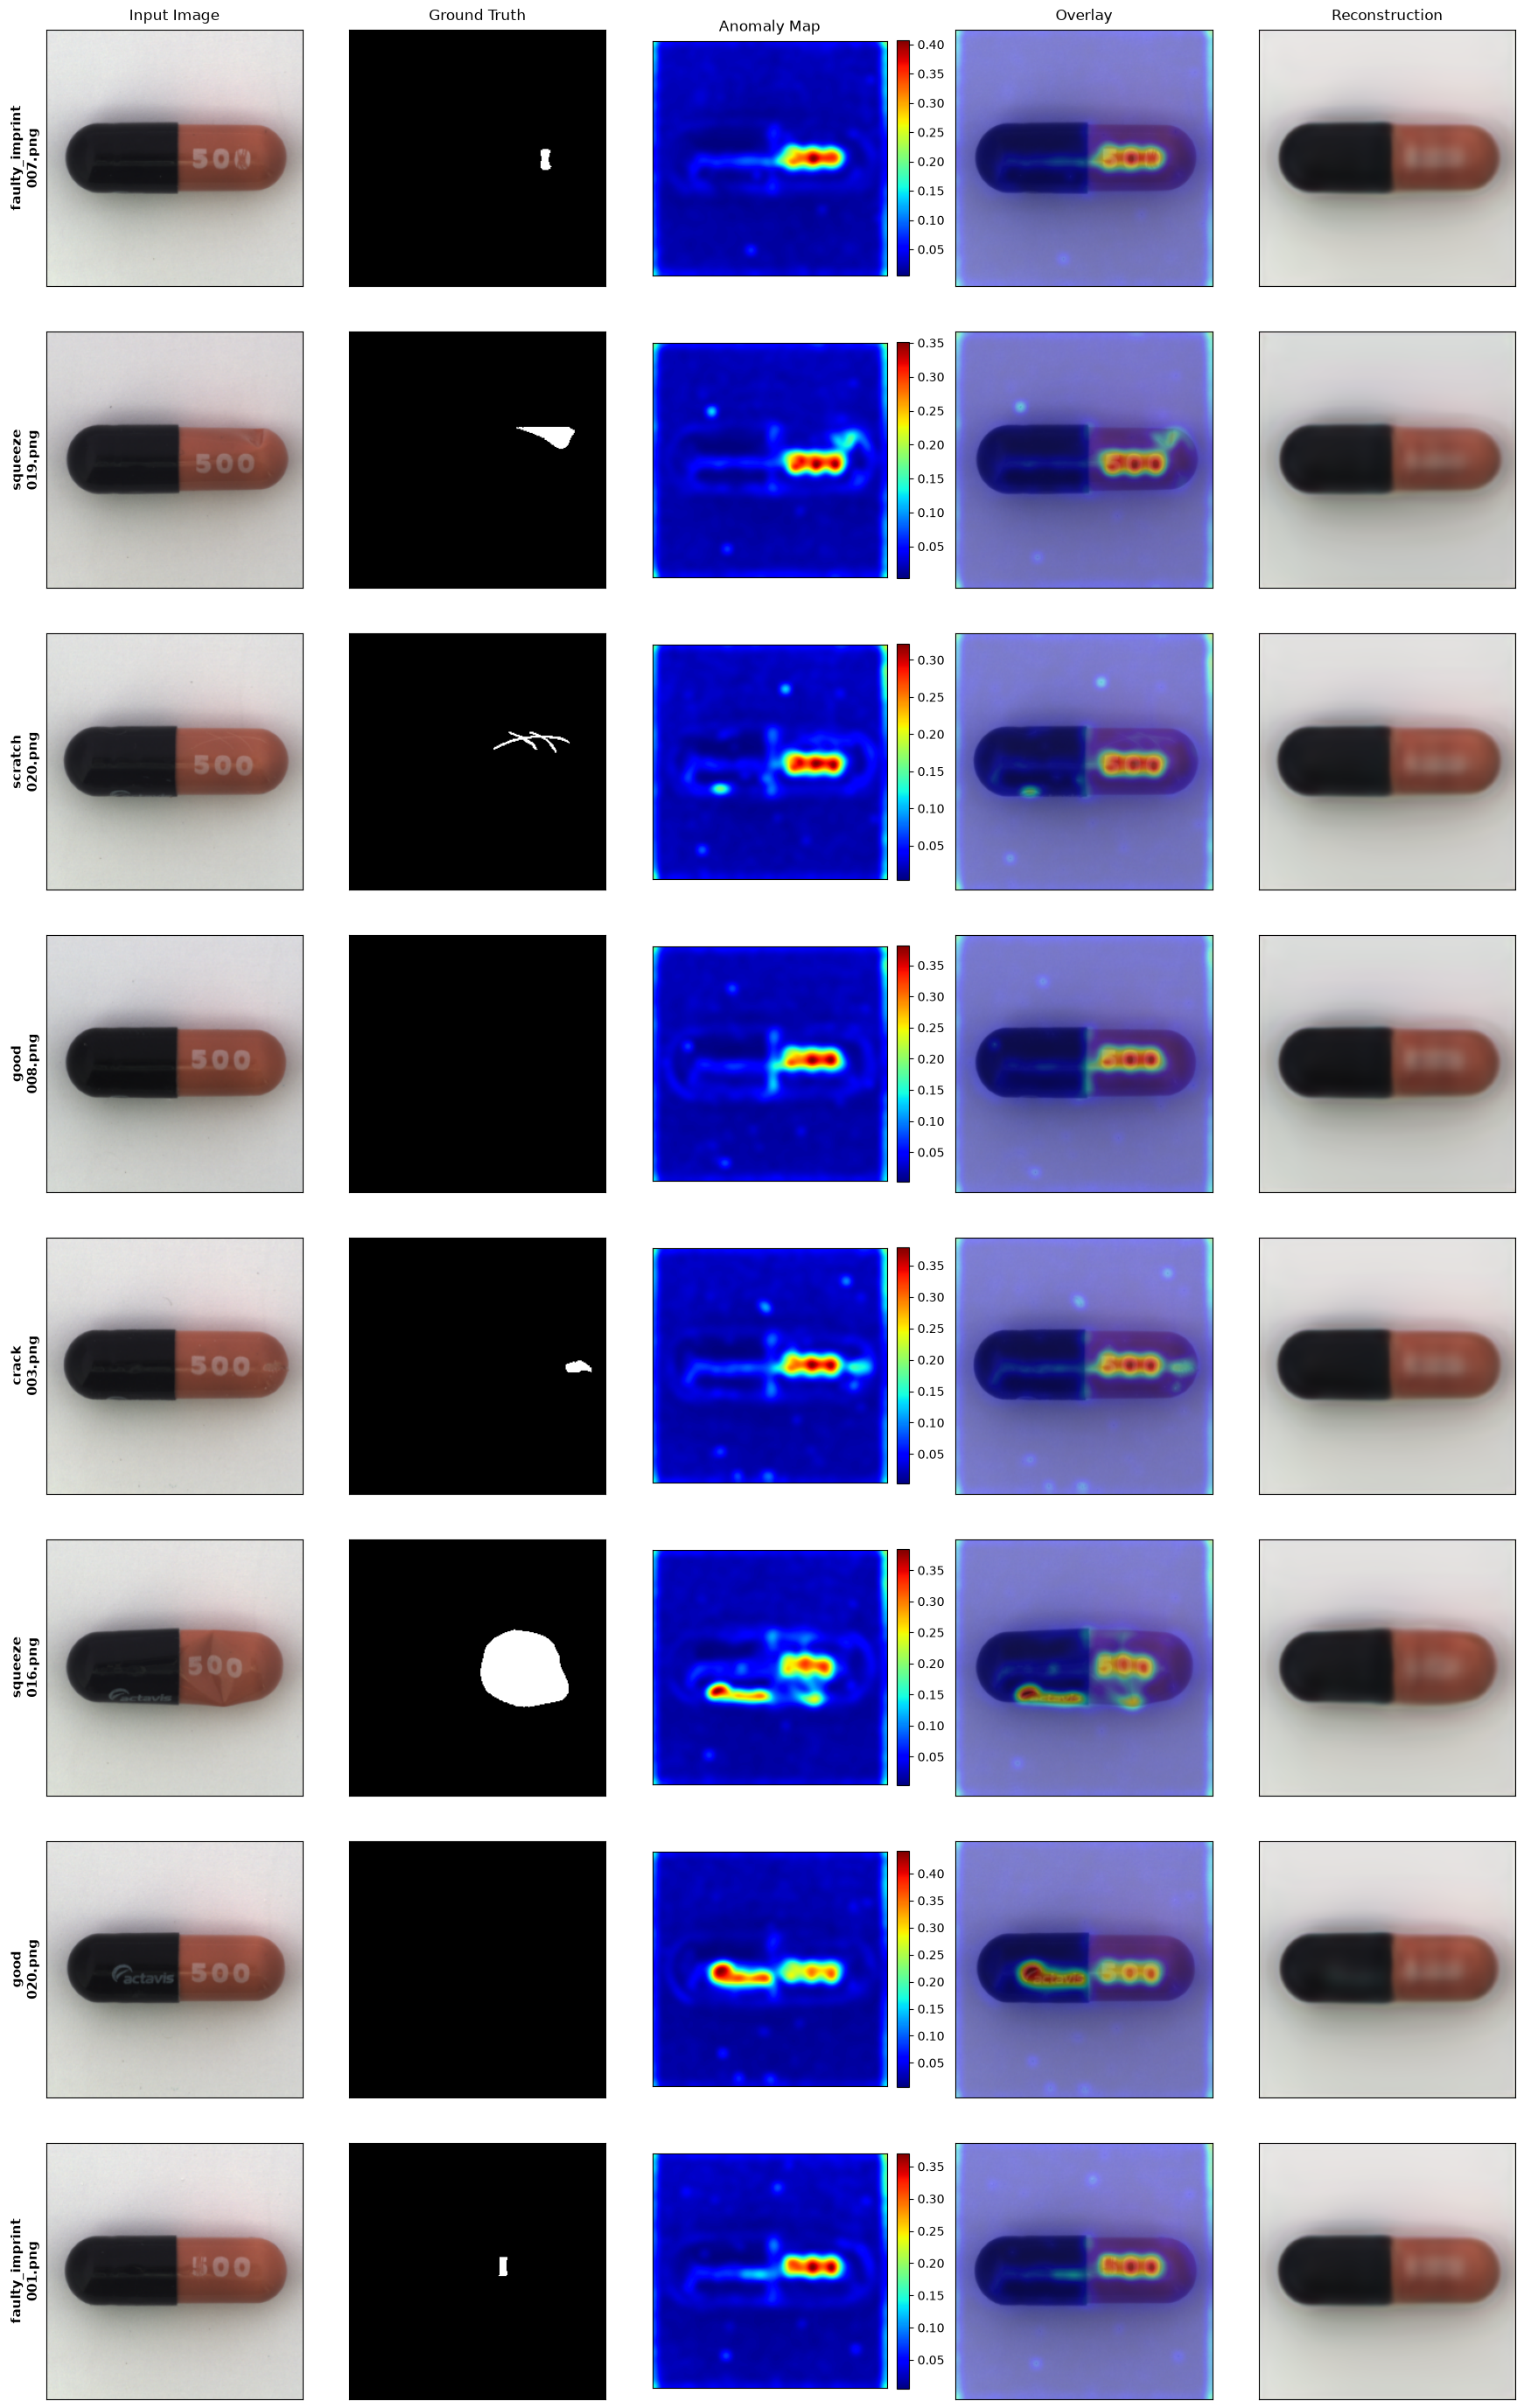

In [4]:
object_name = "capsule"  # Change this to the desired object name
checkpoint_path = f"experiments/pixel_reconstruction/{config['experiment_name']}/{object_name}/checkpoints/best_model.pth"

_, _, test_loader = build_dataloaders(object_name, config)
model = build_model(config, DEVICE, checkpoint_path=checkpoint_path)
visualize_anomalies(model, test_loader, DEVICE, visualize_reconstruction=True, num_samples=8)

In [ ]:
from losses import L1SSIMLoss
config = {

    'experiment_name': 'provaL1loss',

    'device': 'cuda',
    'num_workers': 0,
    'seed': 42,
    'cache_data' : True,

    # dataset
    'img_size': (256, 256),
    'batch_size': 16,

    # training
    'loss_fn': L1SSIMLoss,
    'learning_rate': 1e-3,
    'patience': 7,

    # model
    'model_name': 'Autoencoder',
    'base_channels': 16,
    'num_epochs': 70,
    'output_dir': './experiments/pixel_reconstruction',
    'class_name': 'bottle',  # Specify the class name for training and evaluation
}

set_seed(config['seed'])
DEVICE = get_device(config['device'])
print(f"Using device: {DEVICE}")

classes_to_run = ['bottle', 'wood', 'cable', 'capsule', 'hazelnut']  # List of classes to run experiments on
all_results = {}

for cls in classes_to_run:
    history, metrics = run_experiment_single_class(cls, config)
    all_results[cls] = metrics

df_results = pd.DataFrame.from_dict(all_results, orient='index')
df_results.loc['MEAN'] = df_results.mean()

# results_csv = Path(config['exp_root']) / "benchmark_results.csv"
# df_results.to_csv(results_csv)

display(df_results.round(4))

Random seed set to 42.
Using device: cuda

==============================  Starting class: BOTTLE  ==============================
Training Autoencoder for class 'bottle' on device: cuda


Training:  97%|█████████▋| 68/70 [00:58<00:01,  1.17it/s, train_loss=0.0431, val_loss=0.0451]


Early stopping triggered at epoch 69


Evaluating: 100%|██████████| 6/6 [00:02<00:00,  2.53it/s]



==============================  Starting class: WOOD  ==============================
Training Autoencoder for class 'wood' on device: cuda


Evaluating: 100%|██████████| 5/5 [00:03<00:00,  1.37it/s]


... (7 outputs left out)

Evaluating: 100%|██████████| 9/9 [00:05<00:00,  1.61it/s]



==============================  Starting class: HAZELNUT  ==============================
Training Autoencoder for class 'hazelnut' on device: cuda


Evaluating: 100%|██████████| 7/7 [00:04<00:00,  1.50it/s]


,image_auroc,pixel_auroc,aupro
bottle,0.9706,0.9177,0.7991
wood,0.9632,0.8015,0.7112
cable,0.5365,0.5375,0.4213
capsule,0.6394,0.9130,0.8566
hazelnut,0.8796,0.9746,0.9385
MEAN,0.7979,0.8289,0.7453


Loaded model weights from experiments/pixel_reconstruction//hazelnut/checkpoints/best_model.pth


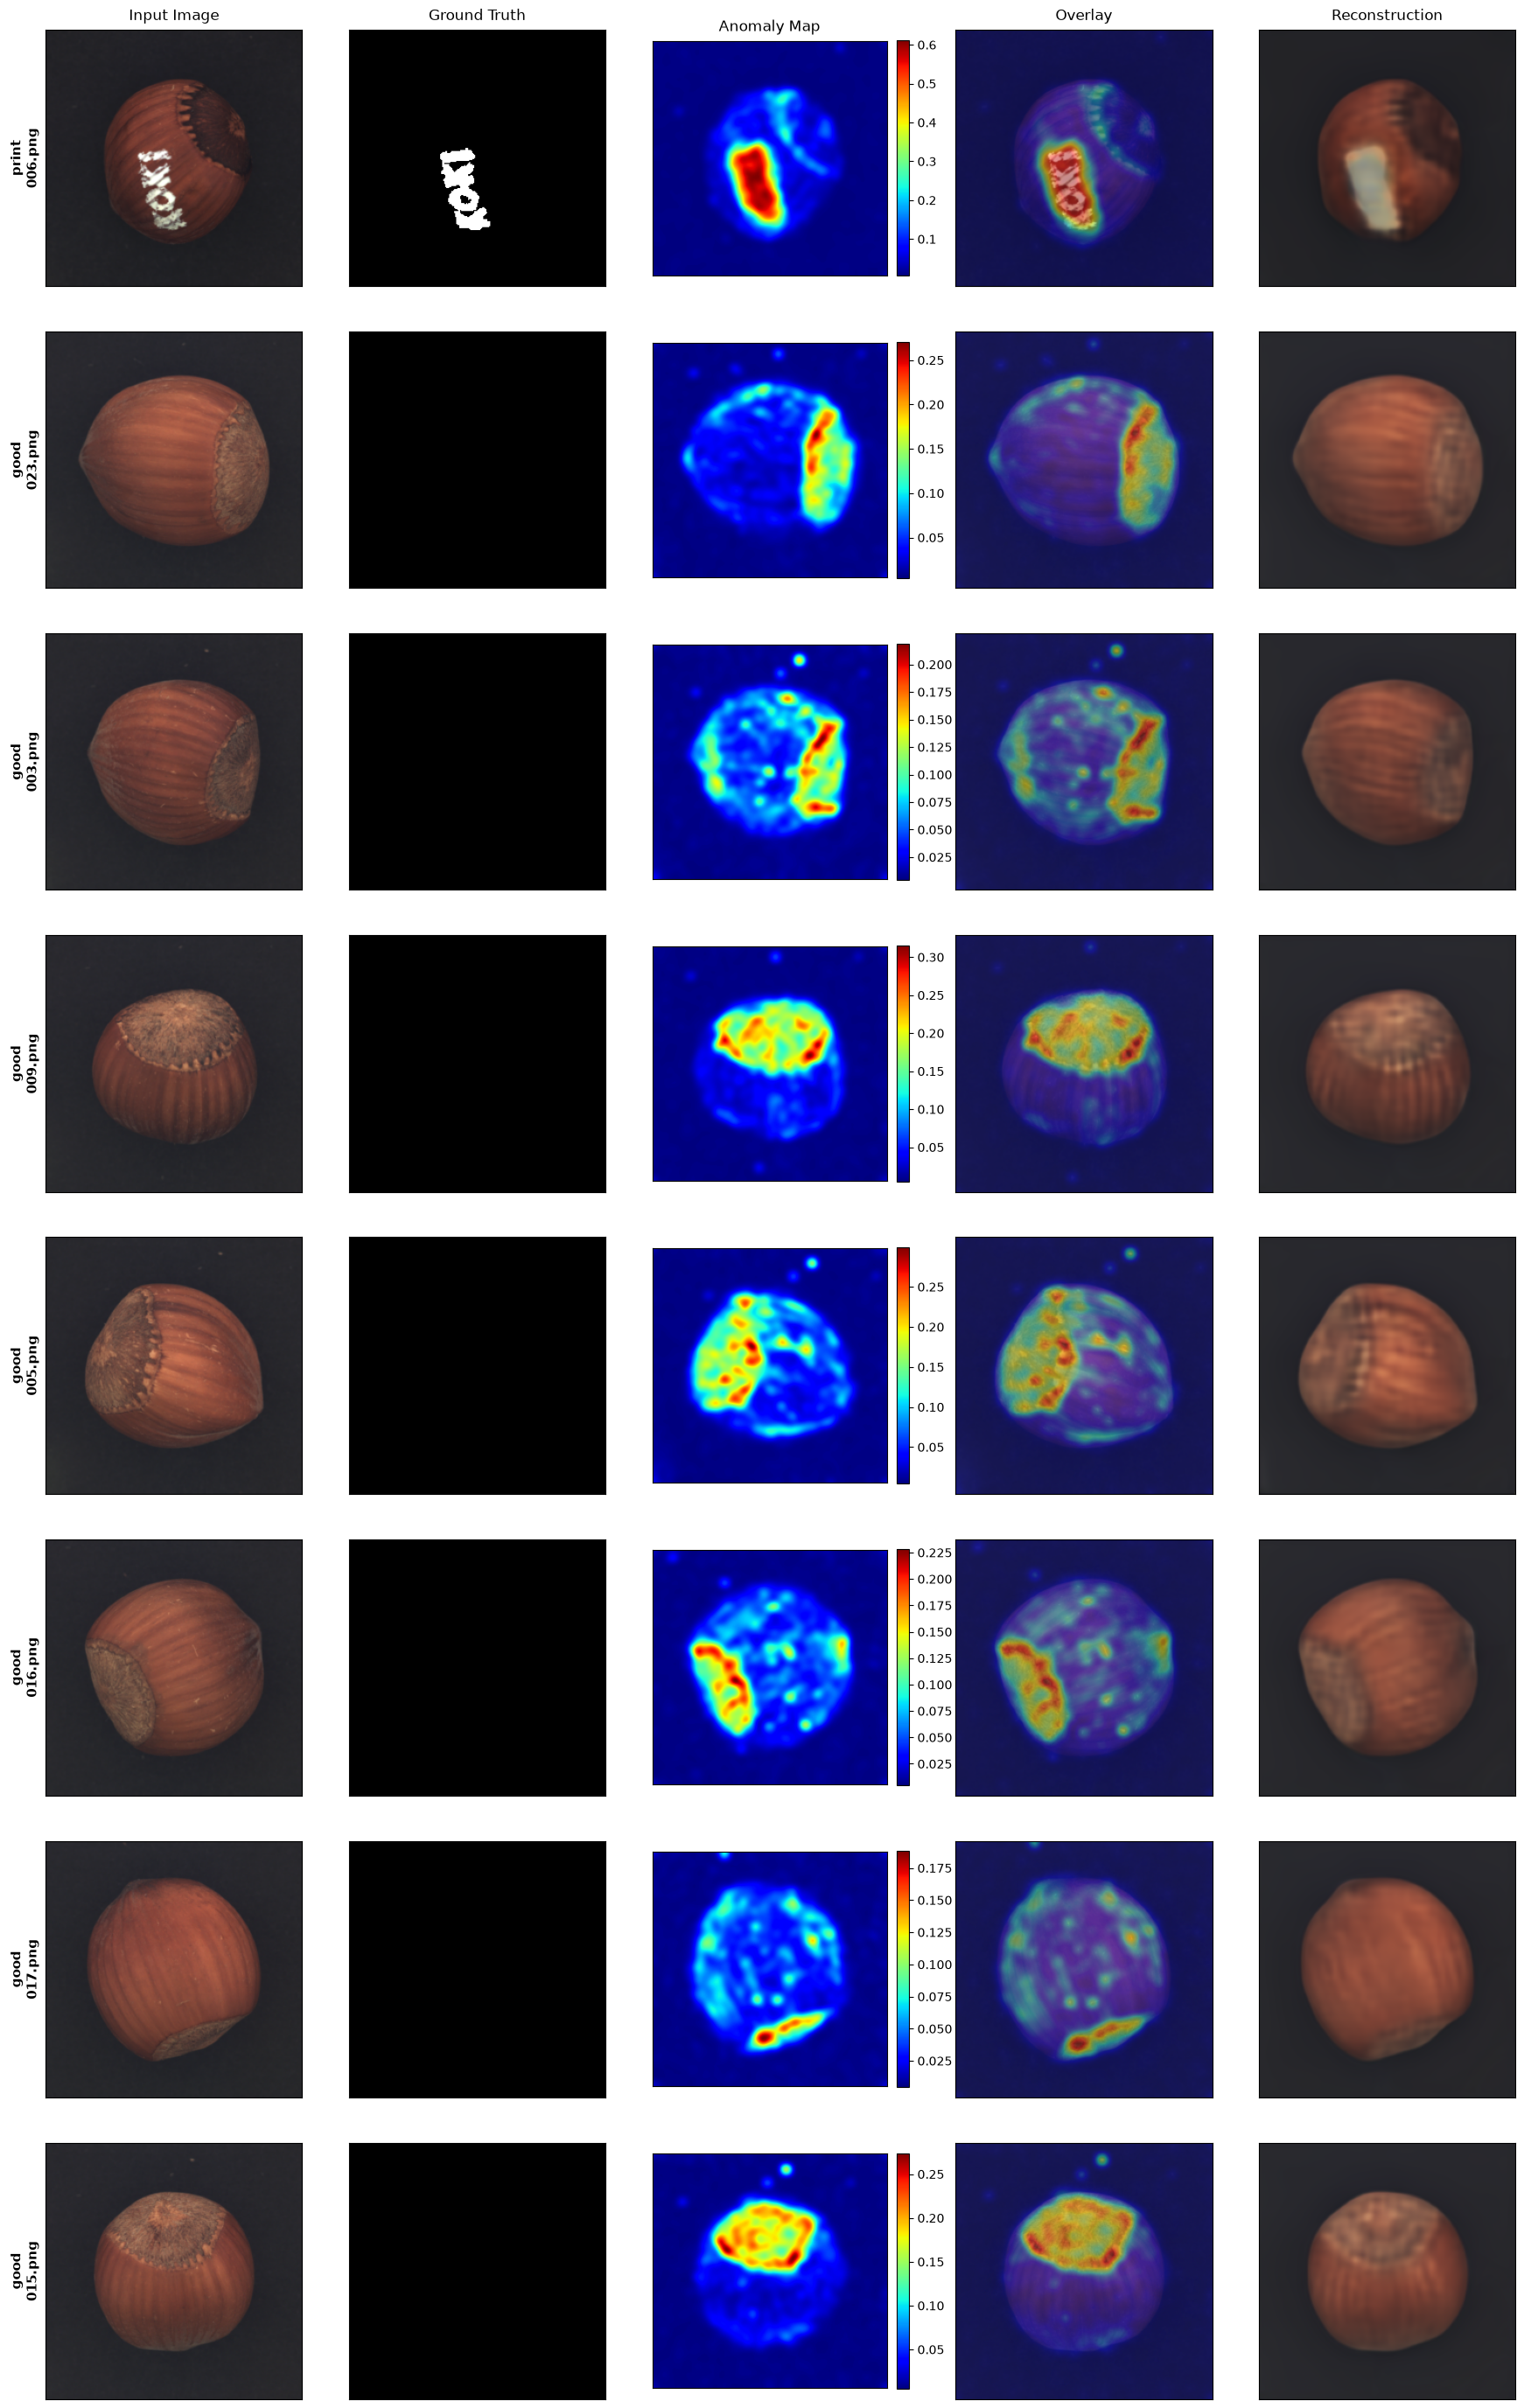

In [10]:
object_name = "hazelnut"  # Change this to the desired object name
checkpoint_path = f"experiments/pixel_reconstruction/{config['experiment_name']}/{object_name}/checkpoints/best_model.pth"

_, _, test_loader = build_dataloaders(object_name, config)
model = build_model(config, DEVICE, checkpoint_path=checkpoint_path)
visualize_anomalies(model, test_loader, DEVICE, visualize_reconstruction=True, num_samples=8)

In [2]:
from losses import L1SSIMLoss
config = {

    'experiment_name': 'prova_bottleneck',

    'device': 'cuda',
    'num_workers': 0,
    'seed': 42,
    'cache_data' : True,

    # dataset
    'img_size': (256, 256),
    'batch_size': 16,

    # training
    'loss_fn': L1SSIMLoss,
    'learning_rate': 1e-3,
    'patience': 7,

    # model
    'model_name': 'Autoencoder',
    'base_channels': 16,
    'num_epochs': 70,
    'output_dir': './experiments/pixel_reconstruction',
    'latent_dim': 256,
    'class_name': 'bottle',  # Specify the class name for training and evaluation
}

set_seed(config['seed'])
DEVICE = get_device(config['device'])
print(f"Using device: {DEVICE}")

classes_to_run = ['bottle', 'wood', 'cable', 'capsule', 'hazelnut']  # List of classes to run experiments on
all_results = {}

for cls in classes_to_run:
    history, metrics = run_experiment_single_class(cls, config)
    all_results[cls] = metrics

df_results = pd.DataFrame.from_dict(all_results, orient='index')
df_results.loc['MEAN'] = df_results.mean()

# results_csv = Path(config['exp_root']) / "benchmark_results.csv"
# df_results.to_csv(results_csv)

display(df_results.round(4))

Random seed set to 42.
Using device: cuda

==============================  Starting class: BOTTLE  ==============================
Using linear bottleneck with latent dimension: 256
Training Autoencoder for class 'bottle' on device: cuda


Training:  39%|███▊      | 27/70 [00:31<00:50,  1.17s/it, train_loss=0.0753, val_loss=0.1156]


Early stopping triggered at epoch 28


Evaluating: 100%|██████████| 6/6 [00:02<00:00,  2.63it/s]



==============================  Starting class: WOOD  ==============================
Using linear bottleneck with latent dimension: 256
Training Autoencoder for class 'wood' on device: cuda


Training:  40%|████      | 28/70 [00:42<01:04,  1.53s/it, train_loss=0.2214, val_loss=0.2264]


... (11 outputs left out)

Training:  51%|█████▏    | 36/70 [01:18<01:14,  2.19s/it, train_loss=0.0546, val_loss=0.0565]


Early stopping triggered at epoch 37


Evaluating: 100%|██████████| 7/7 [00:04<00:00,  1.47it/s]


,image_auroc,pixel_auroc,aupro
bottle,0.7833,0.8218,0.6009
wood,0.9421,0.7266,0.6187
cable,0.6012,0.8682,0.5980
capsule,0.5967,0.9483,0.8536
hazelnut,0.9300,0.9809,0.9401
MEAN,0.7707,0.8692,0.7223


Using linear bottleneck with latent dimension: 256
Loaded model weights from experiments/pixel_reconstruction/prova_bottleneck/hazelnut/checkpoints/best_model.pth


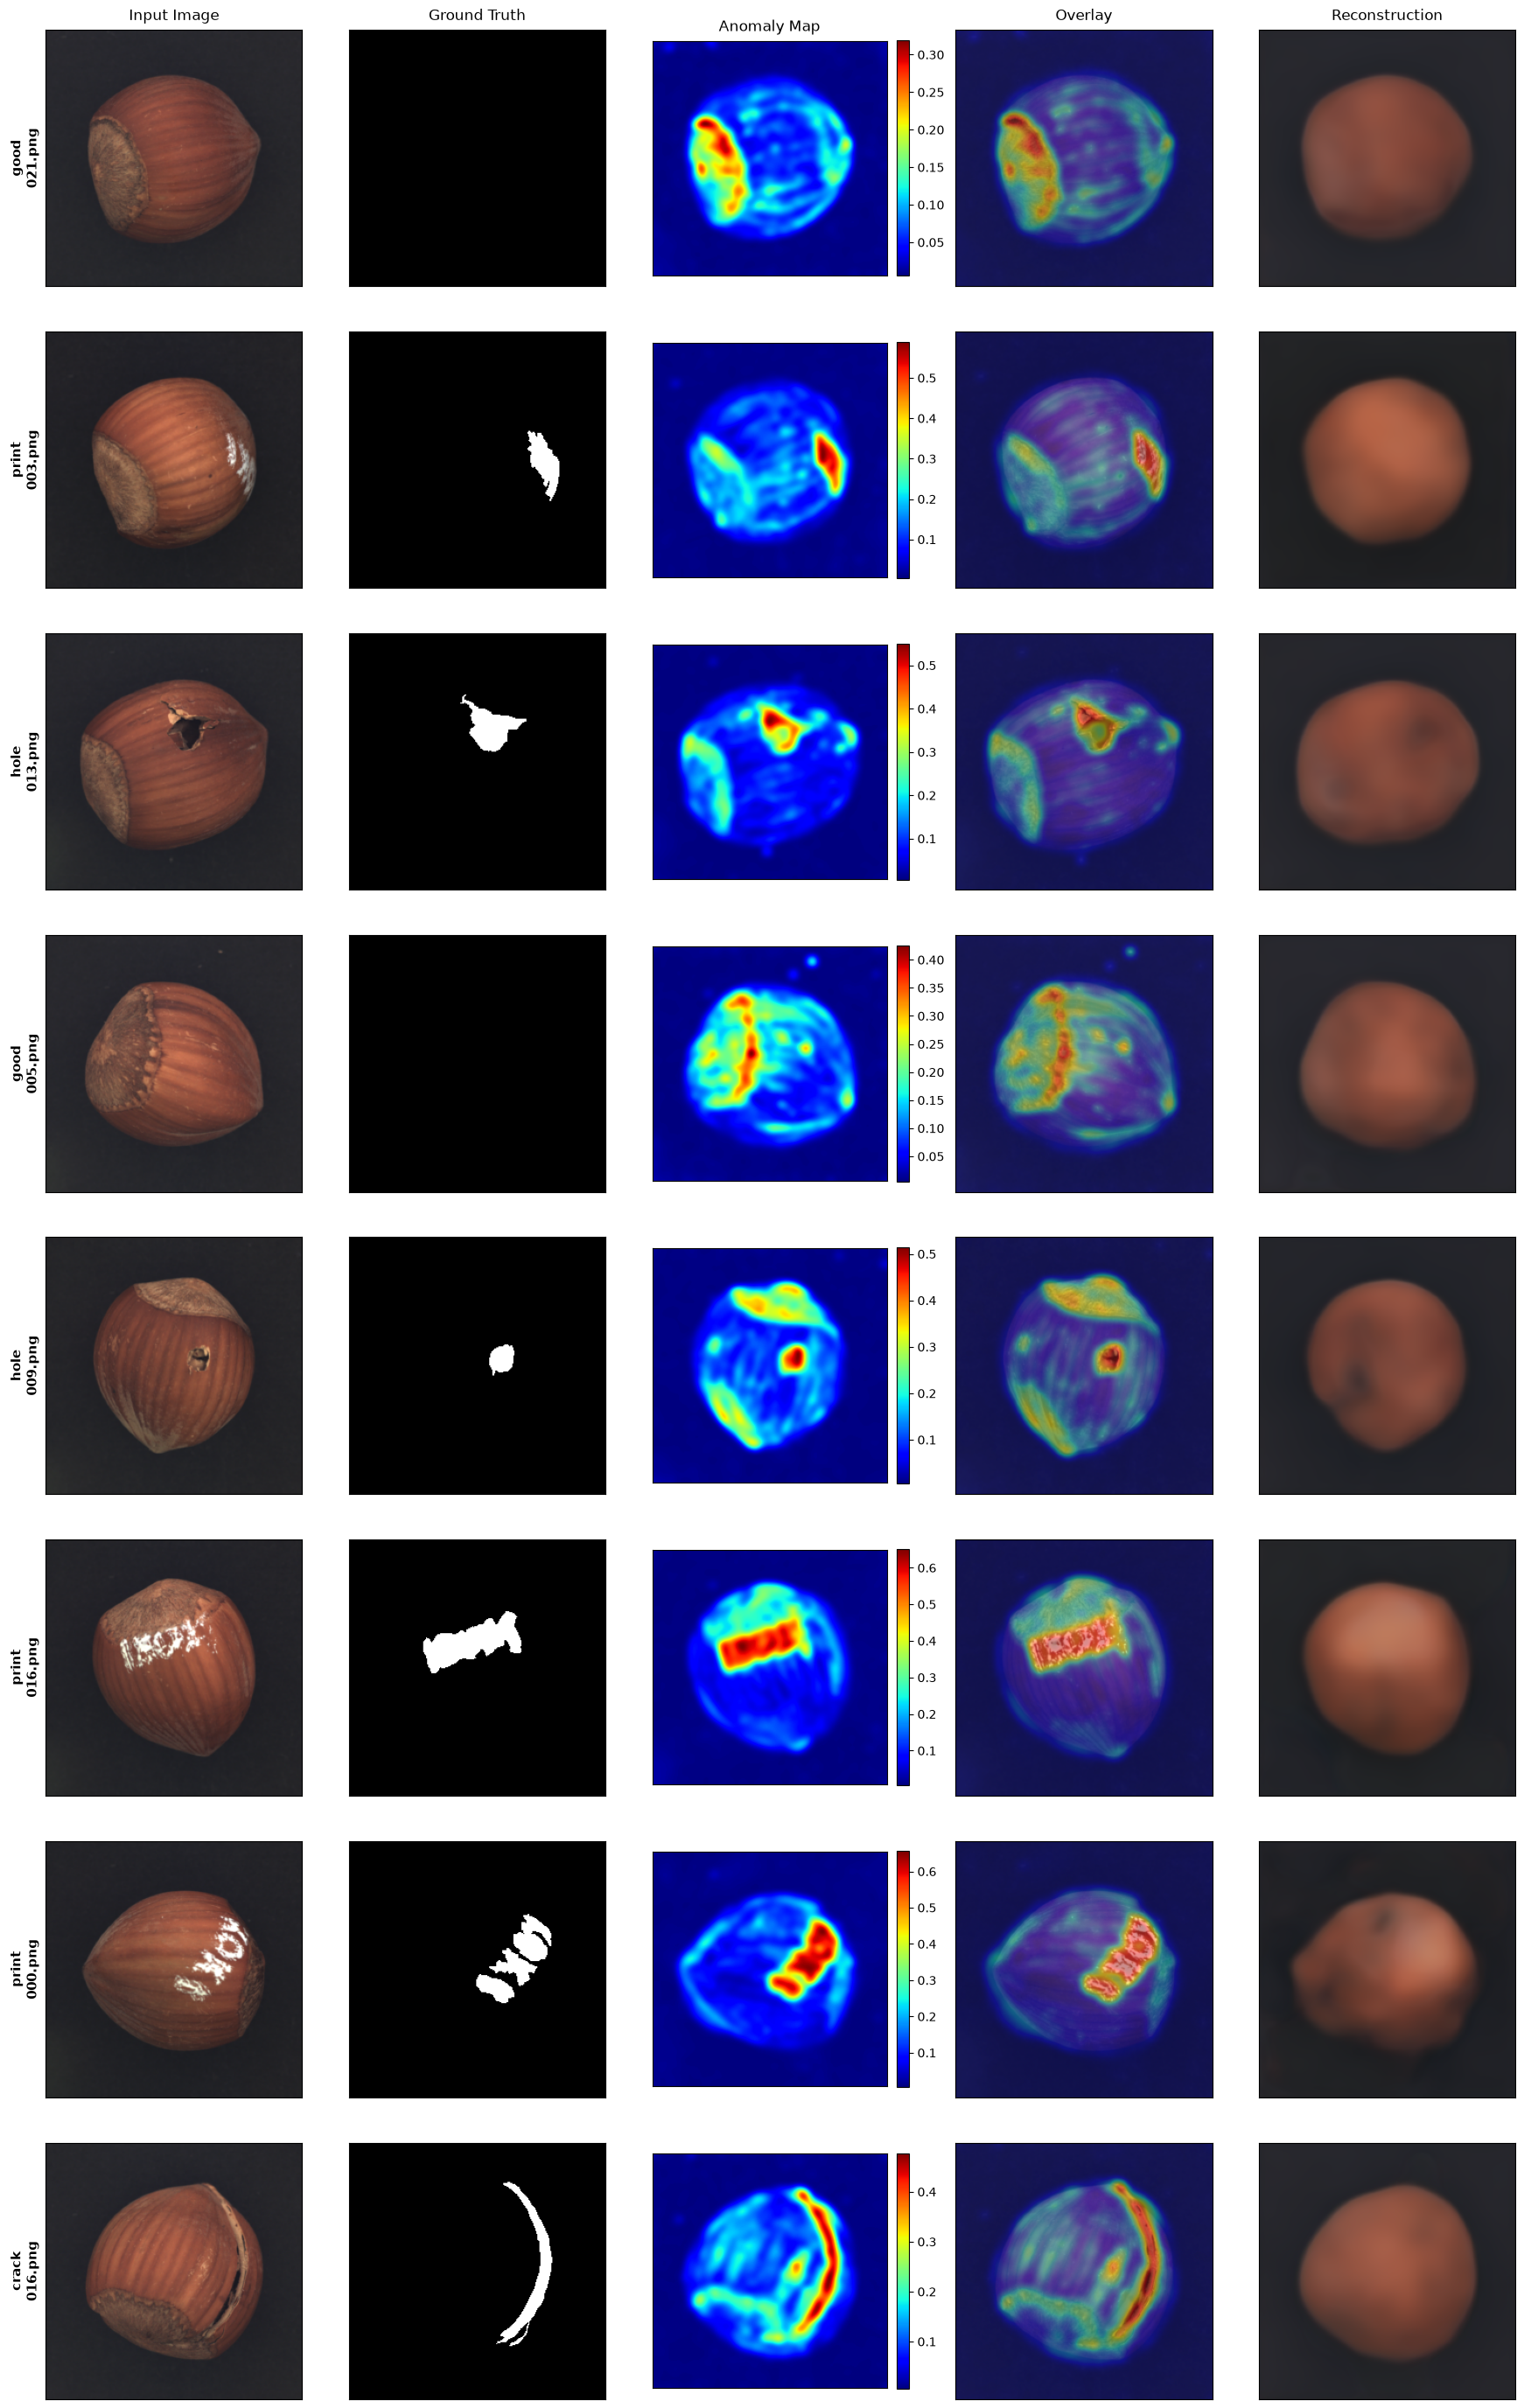

In [3]:
object_name = "hazelnut"  # Change this to the desired object name
checkpoint_path = f"experiments/pixel_reconstruction/{config['experiment_name']}/{object_name}/checkpoints/best_model.pth"

_, _, test_loader = build_dataloaders(object_name, config)
model = build_model(config, DEVICE, checkpoint_path=checkpoint_path)
visualize_anomalies(model, test_loader, DEVICE, visualize_reconstruction=True, num_samples=8)

In [ ]:
from losses import L1SSIMLoss
config = {

    'experiment_name': 'prova_residual_blocks',

    'device': 'cuda',
    'num_workers': 0,
    'seed': 42,
    'cache_data' : True,

    # dataset
    'img_size': (256, 256),
    'batch_size': 16,

    # training
    'loss_fn': L1SSIMLoss,
    'learning_rate': 1e-3,
    'patience': 7,

    # model
    'model_name': 'Autoencoder',
    'base_channels': 16,
    'num_epochs': 70,
    'output_dir': './experiments/pixel_reconstruction',
    'latent_dim': 256,
    'block_type': 'residual',  # Specify the block type for the encoder and decoder
    'class_name': 'bottle',  # Specify the class name for training and evaluation
}

set_seed(config['seed'])
DEVICE = get_device(config['device'])
print(f"Using device: {DEVICE}")

classes_to_run = ['bottle', 'wood', 'cable', 'capsule', 'hazelnut']  # List of classes to run experiments on
all_results = {}

for cls in classes_to_run:
    history, metrics = run_experiment_single_class(cls, config)
    all_results[cls] = metrics

df_results = pd.DataFrame.from_dict(all_results, orient='index')
df_results.loc['MEAN'] = df_results.mean()

# results_csv = Path(config['exp_root']) / "benchmark_results.csv"
# df_results.to_csv(results_csv)

display(df_results.round(4))

Random seed set to 42.
Using device: cuda

==============================  Starting class: BOTTLE  ==============================
Using standard encoder block
Using standard encoder block
Using standard encoder block
Using standard encoder block
Training Autoencoder for class 'bottle' on device: cuda


Training:  23%|██▎       | 16/70 [00:20<01:08,  1.27s/it, train_loss=0.0950, val_loss=0.3020]


KeyboardInterrupt: 